In [1]:
import pandas as pd
import numpy as np
import time
from scipy.optimize import minimize, Bounds

# Load input data
data = pd.read_excel('data/input42u.xlsx')
a = data['a'].values
b = data['b'].values
c = data['c'].values
Minimum_Capacity = data['pmin'].values
Maximum_Capacity = data['pmax'].values
ramp_up = data['rampup'].values
ramp_down = data['rampdown'].values
Unit = data['Unit'].values

penalty_factor = 1e6

# Load power demand
power_demand_data = pd.read_excel('data/power_demand42u.xlsx')
power_demand = power_demand_data['load'].values

# Cost function with penalty
def calculate_fuel_cost_with_penalty(P, a, b, c, demand):
    squaredP = np.multiply(P, P)
    Fuel_Cost = np.divide(np.add(a, np.multiply(b, P) + np.multiply(c, squaredP)), 1000)
    power_difference = np.sum(P) - demand
    penalty_term = penalty_factor * abs(power_difference)
    total_Fuel_Cost = np.sum(Fuel_Cost) + penalty_term
    return total_Fuel_Cost

# TNC optimization wrapper
def tnc(func, initial_guess, bounds):
    result = minimize(
        fun=func,
        x0=initial_guess,
        bounds=bounds,
        method='TNC'
    )
    return result.x, result.fun

# Main optimization loop
all_outputs = []
schedulling = []

for load_counter, demand in enumerate(power_demand, start=1):
    start_time = time.time()
    if load_counter == 1:
        previous_output = None
    else:
        previous_output = all_outputs[-1]['Output']['Power Produced (MW)'].values

    initial_guess = (Minimum_Capacity + Maximum_Capacity) / 2
    bounds = list(zip(Minimum_Capacity, Maximum_Capacity))

    def objective(P):
        return calculate_fuel_cost_with_penalty(P, a, b, c, demand)

    P_opt, cost = tnc(objective, initial_guess, bounds)

    # Enforce capacity and power balance
    for _ in range(10):
        P_opt = np.minimum(np.maximum(P_opt, Minimum_Capacity), Maximum_Capacity)
        power_difference = np.sum(P_opt) - demand
        if power_difference > 0:
            for j in range(len(P_opt)):
                if P_opt[j] > Minimum_Capacity[j]:
                    reduction = min(P_opt[j] - Minimum_Capacity[j], power_difference)
                    P_opt[j] -= reduction
                    power_difference -= reduction
        elif power_difference < 0:
            for j in range(len(P_opt)):
                if P_opt[j] < Maximum_Capacity[j]:
                    increase = min(Maximum_Capacity[j] - P_opt[j], abs(power_difference))
                    P_opt[j] += increase
                    power_difference += increase

    end_time = time.time()

    output = pd.DataFrame({'Unit': Unit, 'Power Produced (MW)': P_opt})
    print("Load Counter: {}".format(load_counter))
    print(f"Output for Power Demand {demand:.2f} MW")
    print(output)
    print(f"Total Power Produced: {np.sum(P_opt):.2f} MW")
    print(f'Total Fuel Cost: Rp {cost}')
    print(f'Computation Time: {end_time - start_time} seconds')
    print('------------------------------------------------\n')

    all_outputs.append({
        'Demand': demand,
        'Output': output,
        'Total Power Produced': np.sum(P_opt),
        'Total Fuel Cost': cost,
        'Computation Time': end_time - start_time
    })

    output_info = {'Demand': demand}
    for unit_index, unit in enumerate(Unit):
        output_info[f'Unit {unit} Power Produced'] = P_opt[unit_index]
        output_info[f'Unit {unit} Cost'] = cost
    schedulling.append(output_info)

# Ramp rate and generation limit check
ramp_rates = []
generation_limits = []
for i in range(1, len(power_demand)):
    prev = all_outputs[i - 1]['Output']['Power Produced (MW)'].values
    curr = all_outputs[i]['Output']['Power Produced (MW)'].values
    ramp_rate = curr - prev
    violations = np.logical_or(ramp_rate > ramp_up, ramp_rate < -ramp_down)

    ramp_rate_info = {'Demand': power_demand[i]}
    generation_limit_info = {'Demand': power_demand[i]}
    for unit_index, unit in enumerate(Unit):
        ramp_rate_info[f'Unit {unit}'] = ramp_rate[unit_index]
        ramp_rate_info[f'Unit {unit} Violation'] = violations[unit_index]
        gen_violation = (curr[unit_index] < Minimum_Capacity[unit_index]) or (curr[unit_index] > Maximum_Capacity[unit_index])
        generation_limit_info[f'Unit {unit}'] = curr[unit_index]
        generation_limit_info[f'Unit {unit} Violation'] = gen_violation
    ramp_rates.append(ramp_rate_info)
    generation_limits.append(generation_limit_info)

# Save to Excel
output_file_path = 'TNC (ED).xlsx'
with pd.ExcelWriter(output_file_path) as writer:
    pd.DataFrame(schedulling).to_excel(writer, sheet_name='Schedulling', index=False)
    pd.DataFrame(all_outputs).to_excel(writer, sheet_name='Summary', index=False)
    pd.DataFrame(ramp_rates).to_excel(writer, sheet_name='Ramp Rates', index=False)
    pd.DataFrame(generation_limits).to_excel(writer, sheet_name='Generation Limits', index=False)

print("All results saved to 'TNC (ED).xlsx'")

Load Counter: 1
Output for Power Demand 8761.42 MW
    Unit  Power Produced (MW)
0      1           294.727295
1      2           294.727295
2      3           290.068549
3      4           290.068558
4      5           444.999839
5      6           444.999839
6      7           445.109035
7      8           130.195522
8      9           130.438693
9     10           130.438693
10    11           124.175349
11    12            58.306844
12    13            59.191370
13    14           119.838786
14    15           119.839085
15    16           257.256096
16    17           260.102730
17    18           260.102730
18    19            10.331183
19    20            10.331183
20    21            87.720998
21    22            89.348288
22    23            89.372527
23    24            87.212295
24    25            85.997041
25    26            85.921063
26    27            85.997041
27    28            85.997042
28    29           400.000000
29    30           400.000000
30    31           

Running F01 (dim=30)...


/var/folders/th/s6s5rhk92_319jmpt7c9n_cw0000gn/T/ipykernel_1727/1631191914.py:56: OptimizeWarning: Unknown solver options: maxiter
  result = minimize(


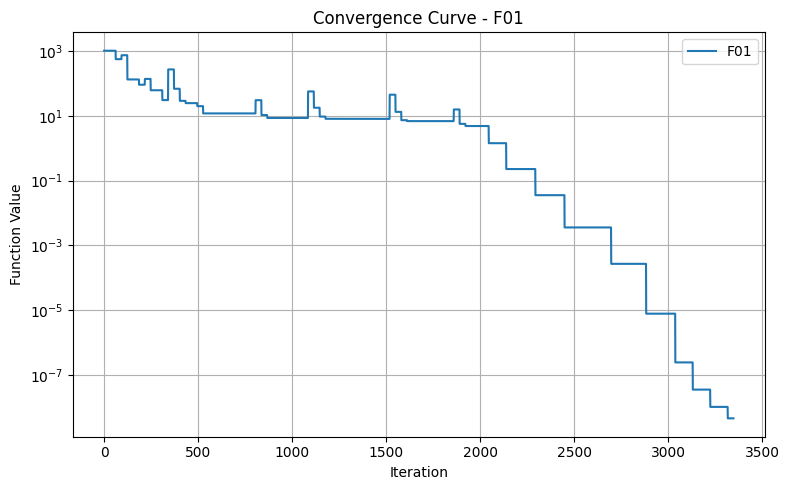

Running F02 (dim=30)...


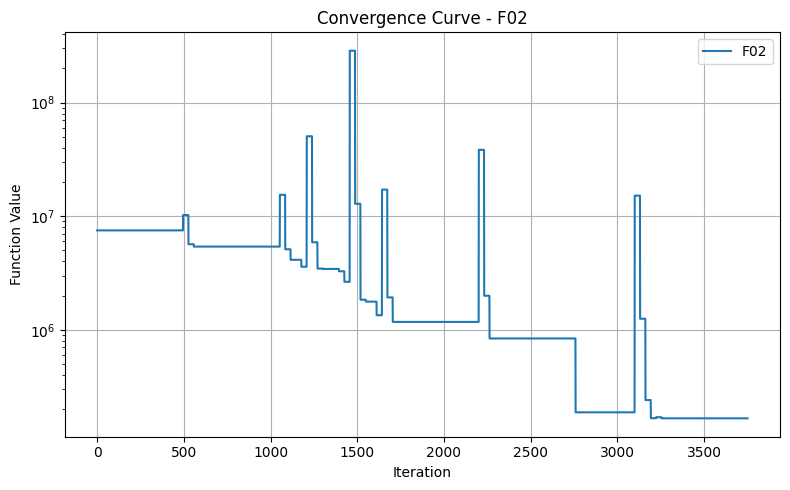

Running F03 (dim=30)...


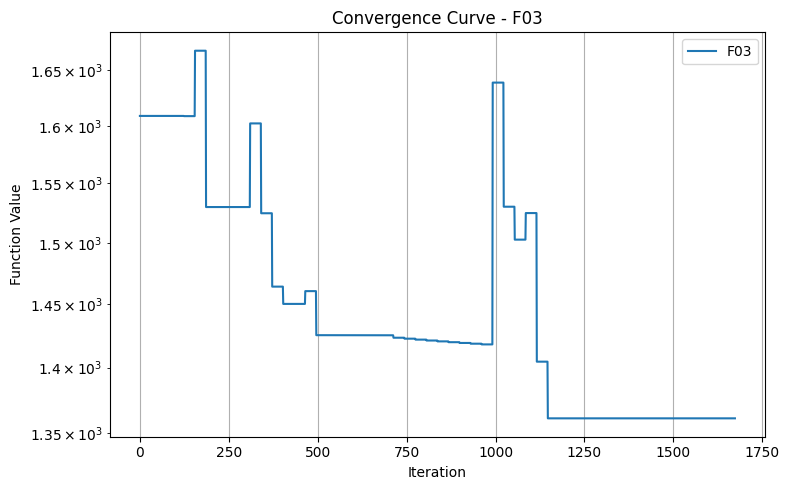

Running F04 (dim=30)...


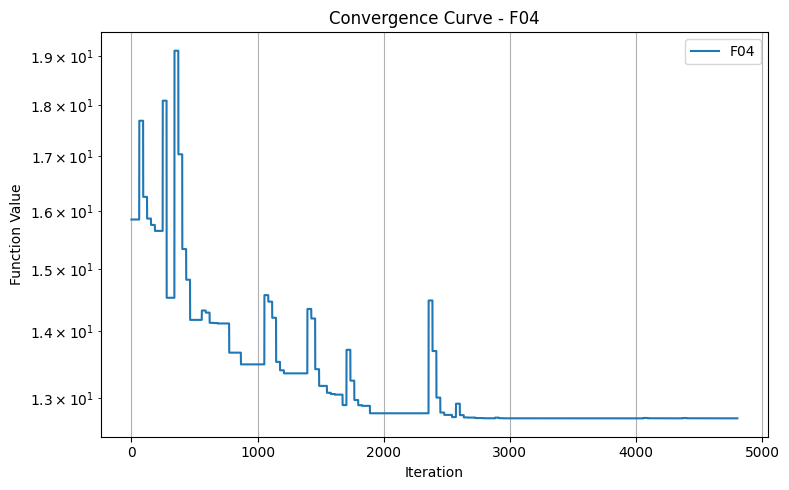

Running F05 (dim=30)...


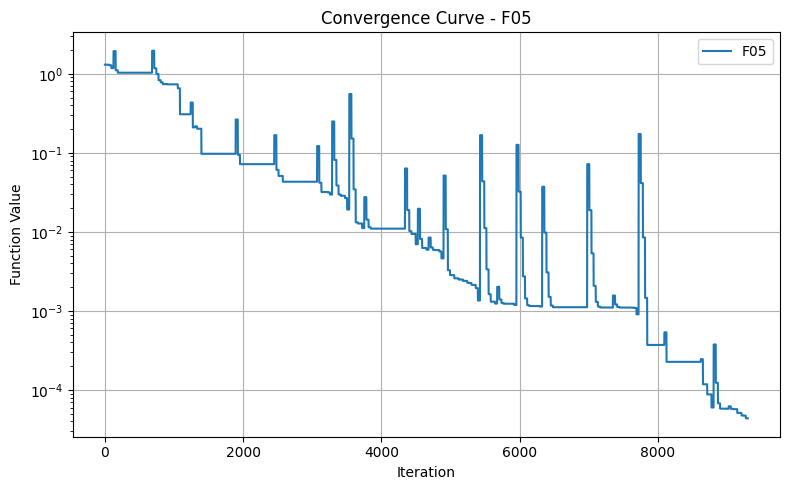

Running F06 (dim=30)...


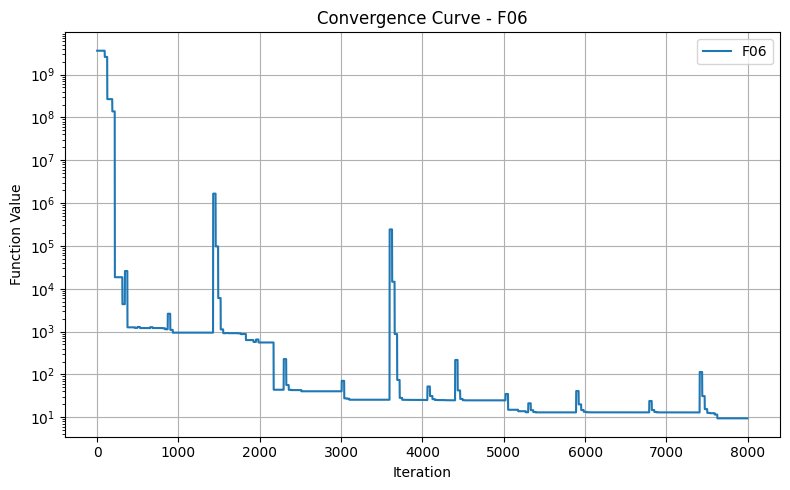

Running F07 (dim=30)...


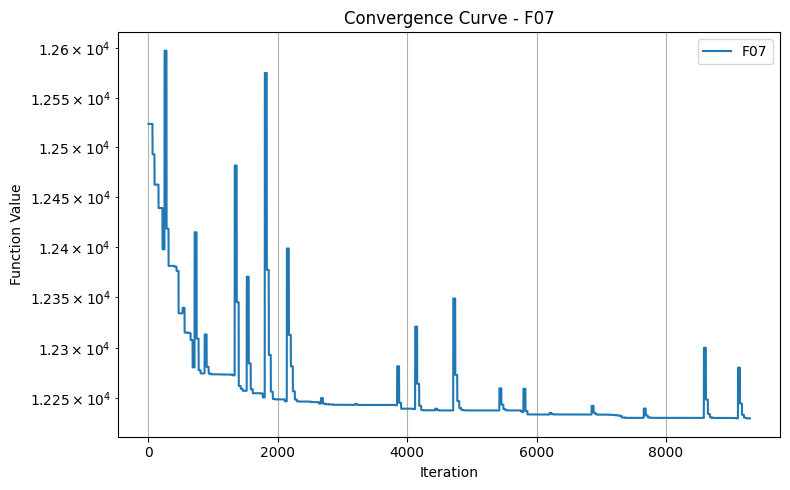

Running F08 (dim=30)...


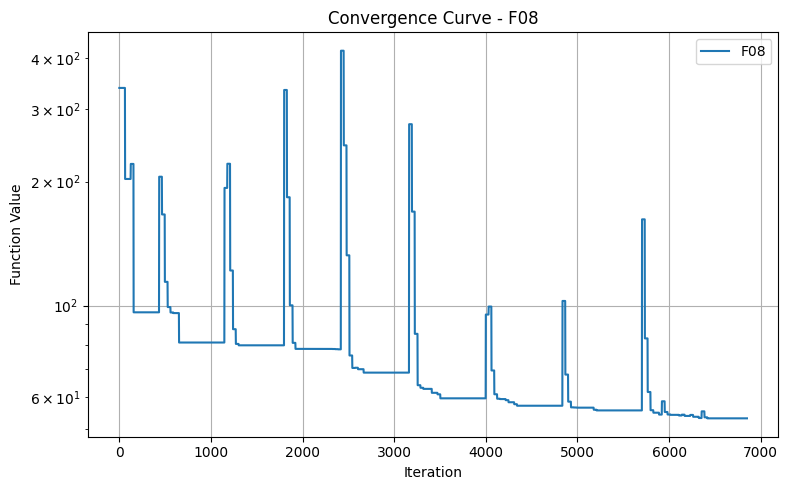

Running F09 (dim=30)...


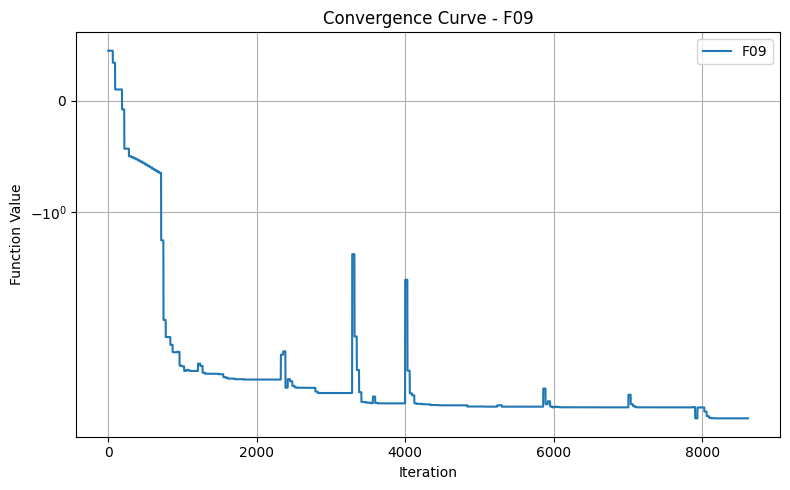

Running F10 (dim=30)...


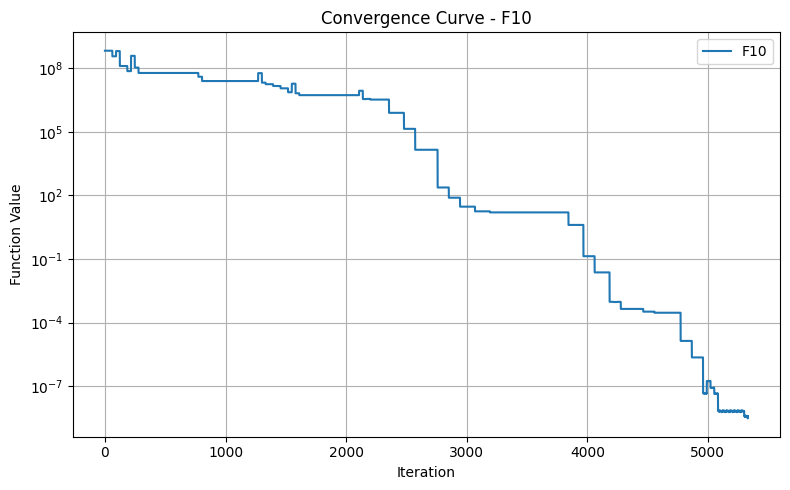

Running F11 (dim=30)...


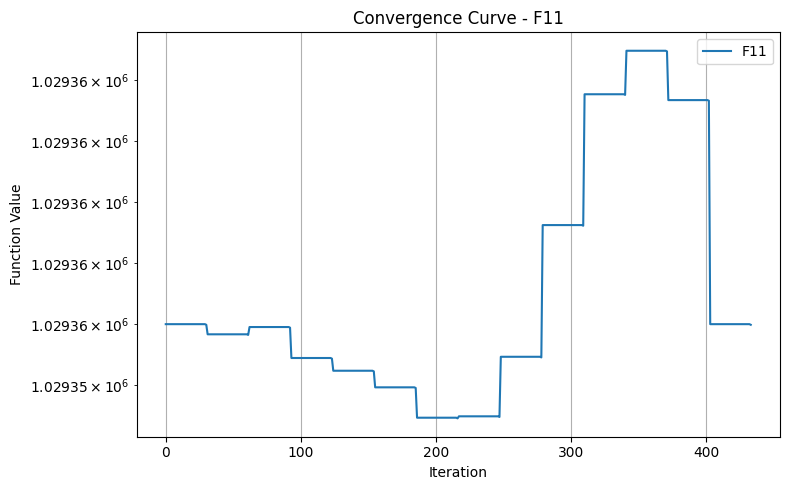

Running F12 (dim=30)...


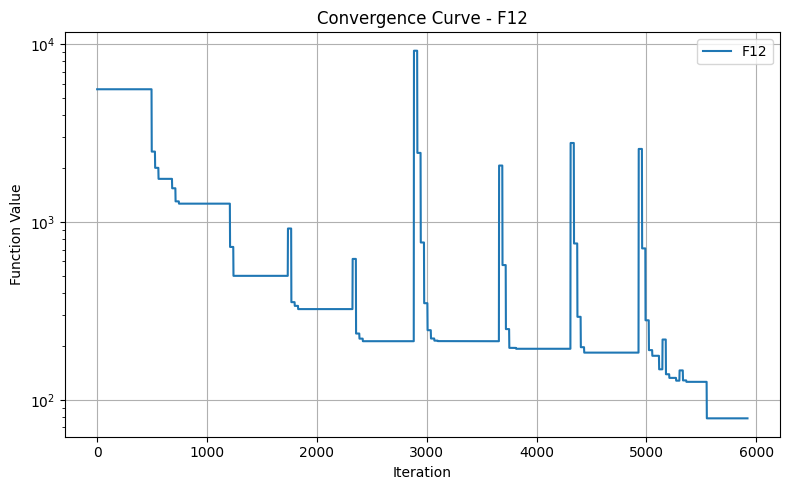

Running F13 (dim=30)...


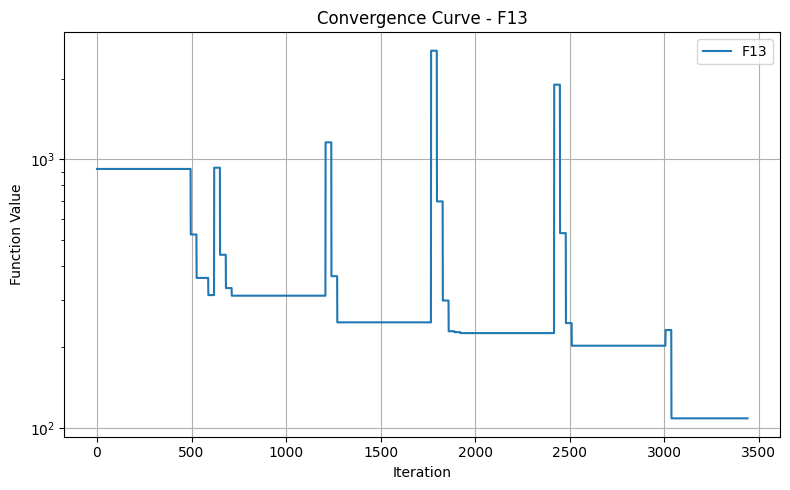

Running F14 (dim=30)...


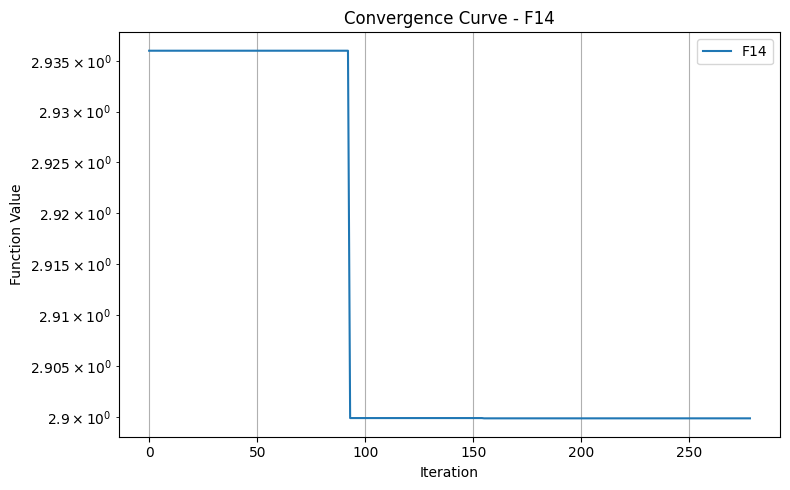

Running F15 (dim=30)...


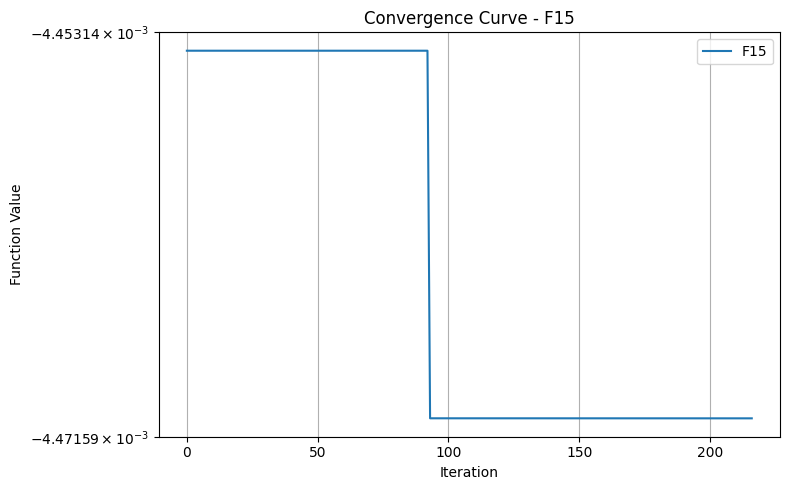

Running F16 (dim=2)...


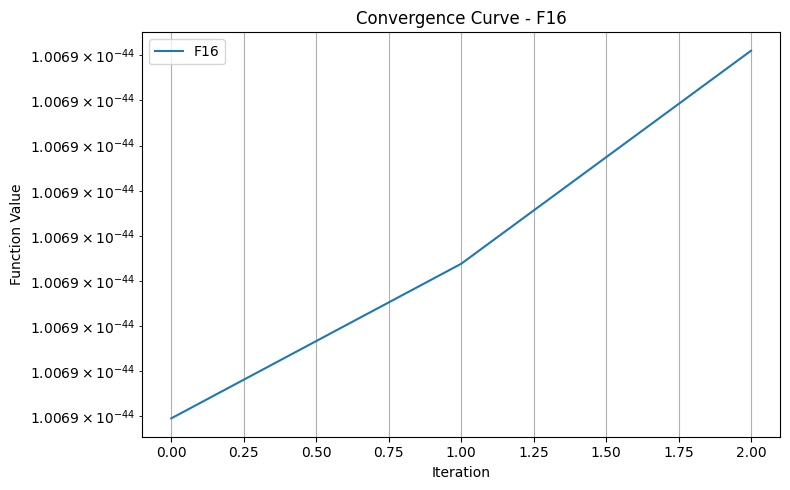

Running F17 (dim=2)...


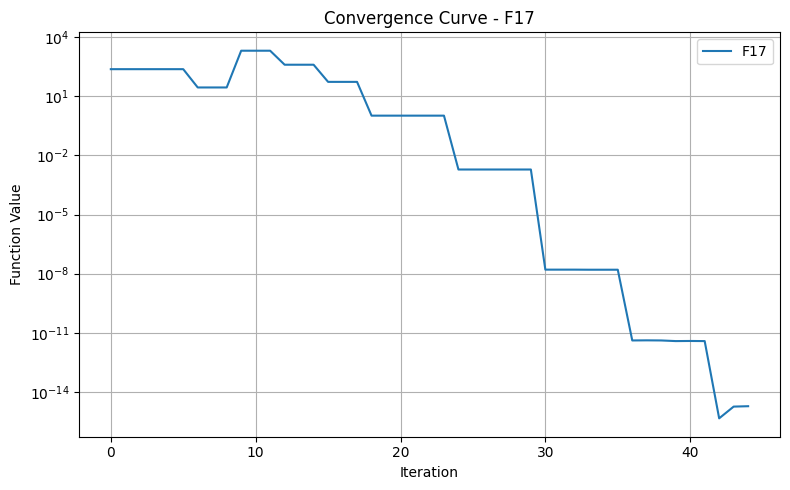

Running F18 (dim=2)...


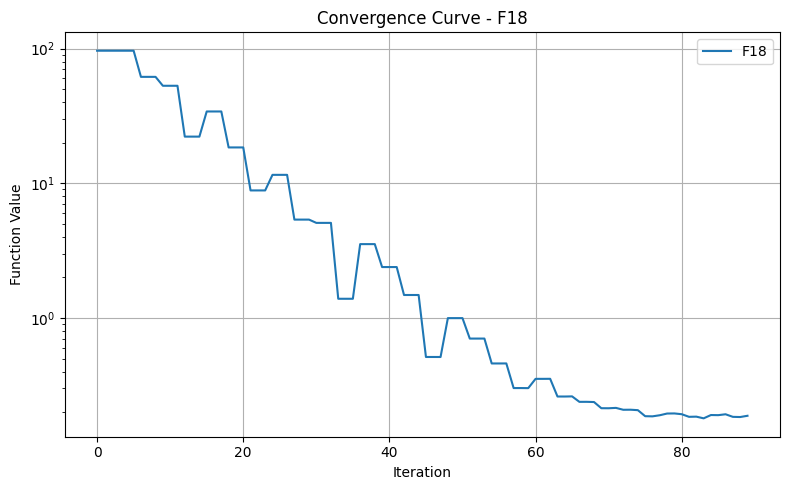

Running F19 (dim=2)...


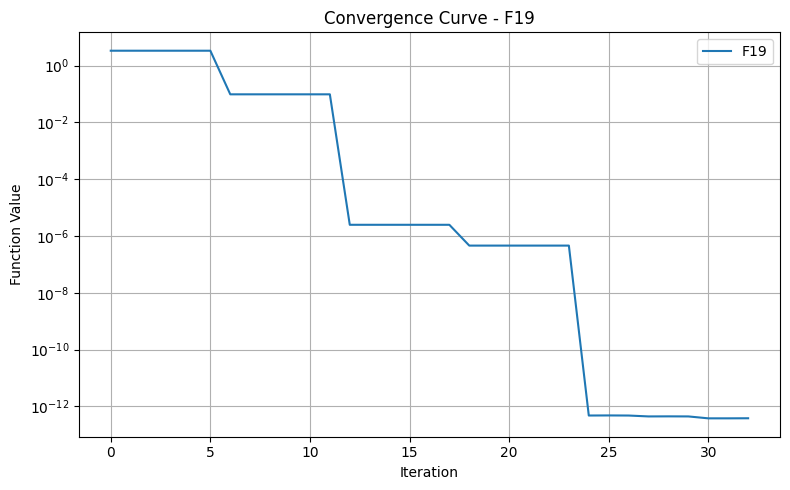

Running F20 (dim=2)...


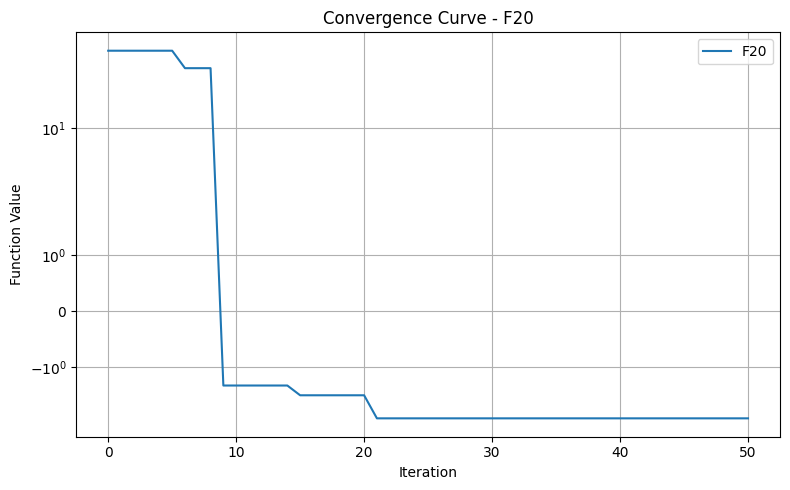

Running F21 (dim=2)...


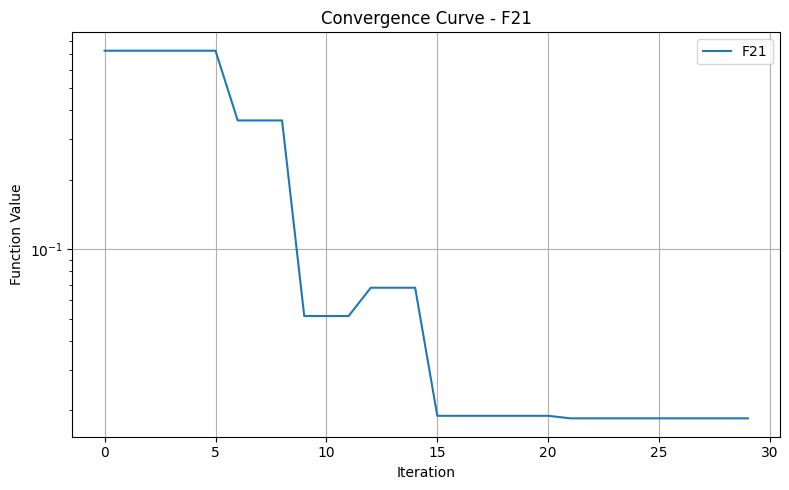

Running F22 (dim=2)...


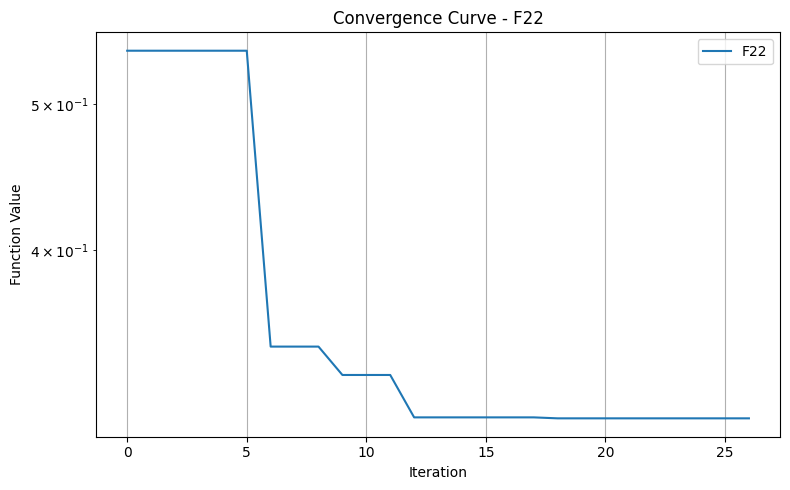

Running F23 (dim=2)...


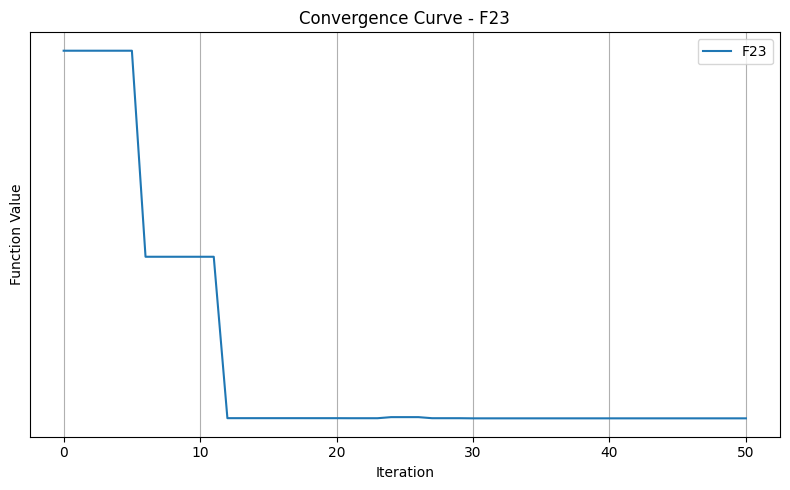


--- Benchmark Results ---
                  Best          Mean        Median         Worst           STD
Function                                                                      
F01       6.155814e-11  1.024822e+00  9.054067e-10  1.085751e+01  3.067255e+00
F02       2.940082e+01  1.005341e+04  7.584663e+02  1.662686e+05  3.040855e+04
F03       3.193838e+02  8.196463e+02  8.649121e+02  1.361184e+03  2.331874e+02
F04       9.989323e+00  1.277457e+01  1.309654e+01  1.469292e+01  1.307635e+00
F05       5.044406e-06  7.281284e-02  1.032850e-02  9.852189e-01  1.848706e-01
F06       4.162191e+00  8.856920e+01  4.398319e+01  4.254873e+02  1.028941e+02
F07       3.955675e+03  1.188683e+04  1.224993e+04  1.242263e+04  1.525406e+03
F08       3.161999e+01  5.419017e+01  5.478714e+01  7.312924e+01  1.146802e+01
F09      -1.155363e+01 -6.777605e+00 -6.424321e+00 -4.204778e+00  1.705872e+00
F10       8.767417e-10  1.286152e+06  2.543419e-08  1.912146e+07  3.895646e+06
F11       1.293992e-09  3

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize

# --- Benchmark Functions (F1–F23) ---
def F1(x): return np.sum(x**2)
def F2(x): return np.sum(100 * (x[1:] - x[:-1]**2)**2 + (x[:-1] - 1)**2)
def F3(x): return np.sum(x**2 - 10 * np.cos(2 * np.pi * x) + 10)
def F4(x): return -20 * np.exp(-0.2*np.sqrt(np.mean(x**2))) - np.exp(np.mean(np.cos(2*np.pi*x))) + 20 + np.e
def F5(x): return np.sum(x**2)/4000 - np.prod(np.cos(x / np.sqrt(np.arange(1, len(x)+1)))) + 1
def F6(x): return np.sum(x**2) + (np.sum(0.5 * np.arange(1, len(x)+1) * x))**2 + (np.sum(0.5 * np.arange(1, len(x)+1) * x))**4
def F7(x): return 418.9829 * len(x) - np.sum(x * np.sin(np.sqrt(np.abs(x))))
def F8(x): 
    w = 1 + (x - 1) / 4
    return np.sin(np.pi * w[0])**2 + np.sum((w[:-1] - 1)**2 * (1 + 10*np.sin(np.pi*w[:-1] + 1)**2)) + (w[-1]-1)**2 * (1 + np.sin(2*np.pi*w[-1])**2)
def F9(x): return -np.sum(np.sin(x) * np.sin(((np.arange(1, len(x)+1) * x**2) / np.pi))**20)
def F10(x): return x[0]**2 + 1e6 * np.sum(x[1:]**2)
def F11(x): return np.sum(np.abs(x)**(2 + 4*np.arange(len(x))/(len(x)-1)))
def F12(x): return np.sum([np.sum(x[:i])**2 for i in range(1, len(x)+1)])
def F13(x): return np.sum((x - 1)**2) - np.sum(x[:-1] * x[1:])
def F14(x): return 1 - np.cos(2*np.pi*np.sqrt(np.sum(x**2))) + 0.1*np.sqrt(np.sum(x**2))
def F15(x): return - (1 + np.cos(12*np.sqrt(np.sum(x**2)))) / (0.5*np.sum(x**2) + 2)
def F16(x): return -np.cos(x[0]) * np.cos(x[1]) * np.exp(-(x[0]-np.pi)**2 - (x[1]-np.pi)**2)
def F17(x): return (x[0] + 2*x[1] - 7)**2 + (2*x[0] + x[1] - 5)**2
def F18(x): return 100*np.sqrt(abs(x[1] - 0.01*x[0]**2)) + 0.01*abs(x[0] + 10)
def F19(x): return 0.26*(x[0]**2 + x[1]**2) - 0.48*x[0]*x[1]
def F20(x): return np.sin(x[0]+x[1]) + (x[0]-x[1])**2 - 1.5*x[0] + 2.5*x[1] + 1
def F21(x): return 0.5 + (np.sin(x[0]**2 - x[1]**2)**2 - 0.5)/(1 + 0.001*(x[0]**2 + x[1]**2))**2
def F22(x): return 0.5 + (np.cos(np.sin(abs(x[0]**2 - x[1]**2)))**2 - 0.5)/(1 + 0.001*(x[0]**2 + x[1]**2))**2
def F23(x): 
    r = np.sqrt(x[0]**2 + x[1]**2)
    z = np.clip(abs(1 - r / np.pi), -50, 50)
    try:
        exp_term = np.exp(z)
    except:
        exp_term = 1e10
    return -abs(np.sin(x[0]) * np.cos(x[1]) * exp_term)

benchmark_functions = {
    f"F{str(i+1).zfill(2)}": f for i, f in enumerate([
        F1, F2, F3, F4, F5, F6, F7, F8, F9, F10, F11, F12, F13, F14, F15,
        F16, F17, F18, F19, F20, F21, F22, F23
    ])
}

# ----- TNC -----
def tnc(func, initial_guess):
    convergence_curve = []

    def wrapped_func(x):
        val = func(x)
        convergence_curve.append(val)
        return val

    result = minimize(
        fun=wrapped_func,
        x0=initial_guess,
        method='TNC',
        constraints=[],
        options={'maxiter': 1000, 'disp': False}
    )
    return result.x, result.fun, convergence_curve

# ----- Run Single Benchmark -----
def run_benchmark(func, dim, runs=30, low=-10, high=10):
    results = []
    convergence = None
    for _ in range(runs):
        x0 = np.random.uniform(low, high, size=dim)
        try:
            result, val, curve = tnc(func, x0)
            if np.isfinite(val):
                results.append(val)
                if convergence is None or (len(curve) < len(convergence)):
                    convergence = curve
        except Exception as e:
            print(f"[!] Error during benchmark run: {e}")
            results.append(np.nan)
    return {
        'Best': np.nanmin(results),
        'Mean': np.nanmean(results),
        'Median': np.nanmedian(results),
        'Worst': np.nanmax(results),
        'STD': np.nanstd(results),
        'Convergence': convergence
    }

# --- Run All Benchmarks with Plotting ---
def run_all_benchmarks(dim=30, runs=30):
    summary = []
    for name, func in benchmark_functions.items():
        d = 2 if name in ['F16','F17','F18','F19','F20','F21','F22','F23'] else dim
        print(f"Running {name} (dim={d})...")
        stats = run_benchmark(func, dim=d, runs=runs)
        convergence = stats.pop('Convergence')

        if convergence:
            plt.figure(figsize=(8, 5))
            plt.plot(convergence, label=name)
            if all(val > 0 for val in convergence):
                plt.yscale('log')
            else:
                plt.yscale('symlog')
            plt.xlabel('Iteration')
            plt.ylabel('Function Value')
            plt.title(f'Convergence Curve - {name}')
            plt.grid(True)
            plt.legend()
            plt.tight_layout()
            plt.show()

        stats['Function'] = name
        summary.append(stats)
    return pd.DataFrame(summary).set_index("Function")

# --- Execute All ---
results = run_all_benchmarks(dim=30, runs=30)
print("\n--- Benchmark Results ---")
print(results)

# Save Excel
results.to_excel('Benchmark_TNC.xlsx')
print("\n✅ Results saved to Benchmark_TNC.xlsx")

Running F01 (dim=30)...


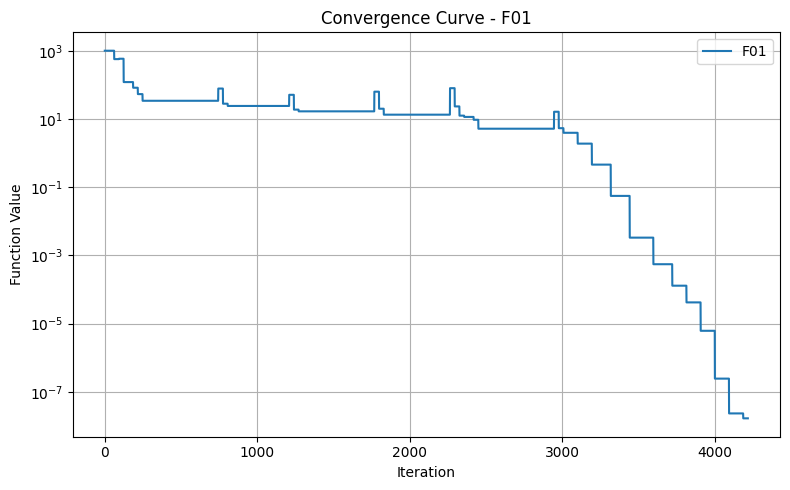

Running F02 (dim=30)...


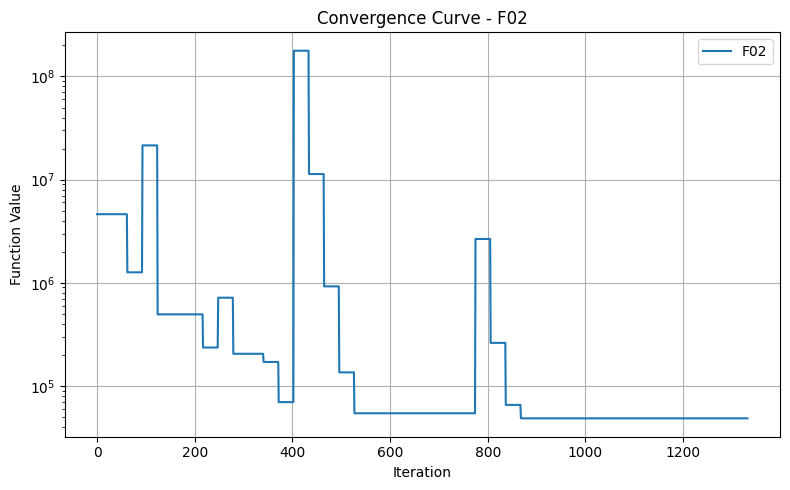

Running F03 (dim=30)...


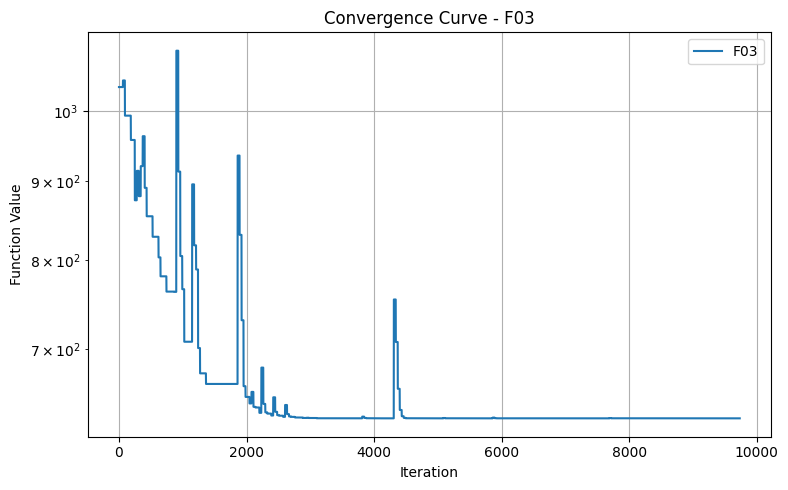

Running F04 (dim=30)...


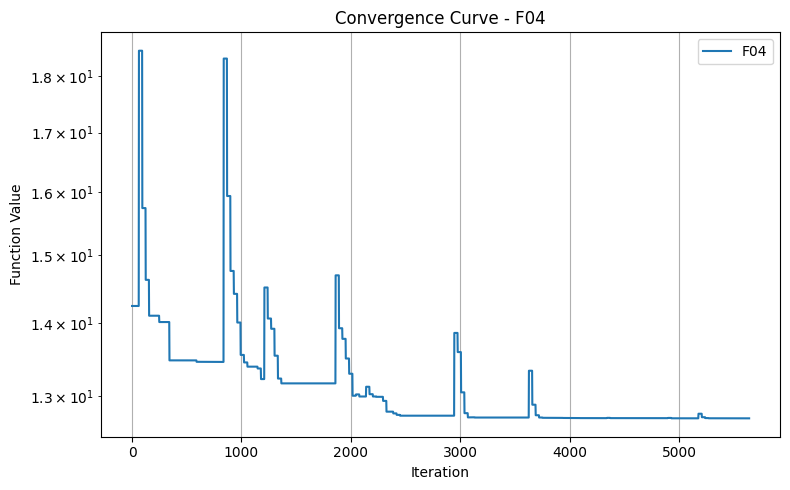

Running F05 (dim=30)...


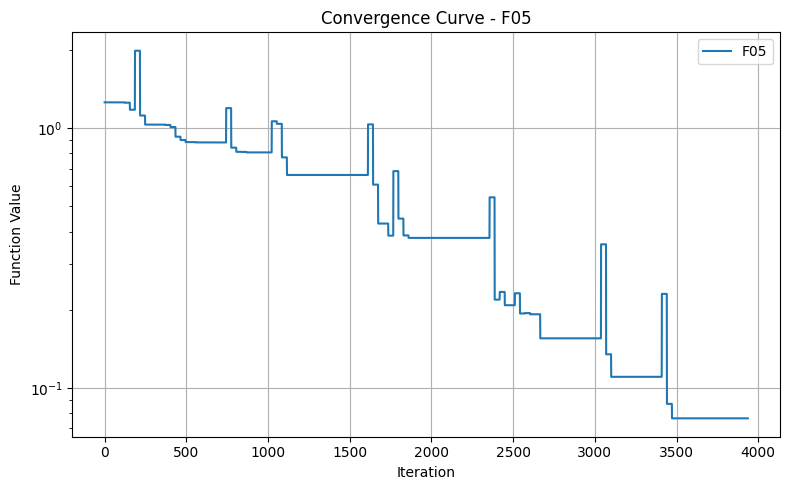

Running F06 (dim=30)...


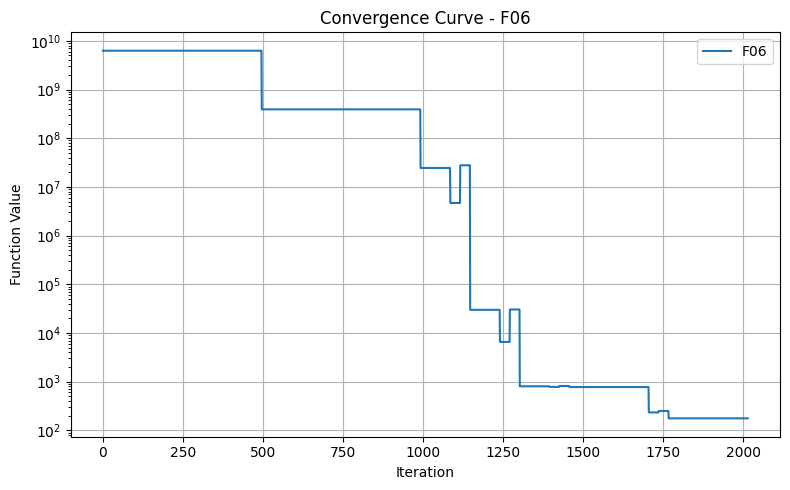

Running F07 (dim=30)...


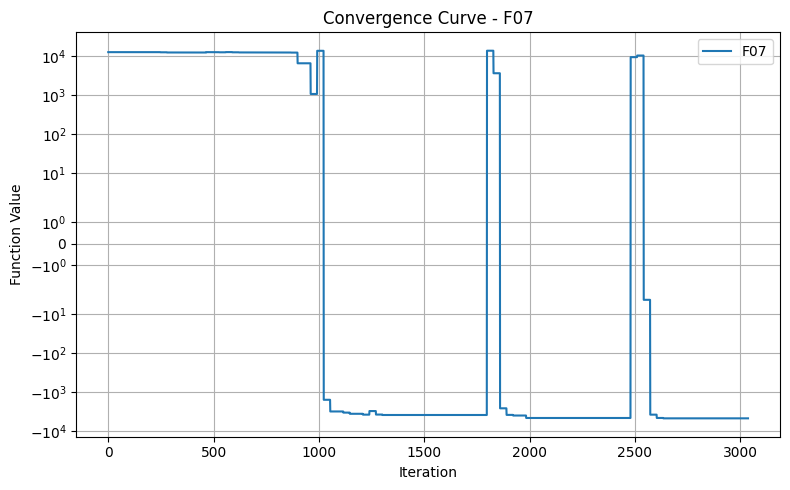

Running F08 (dim=30)...


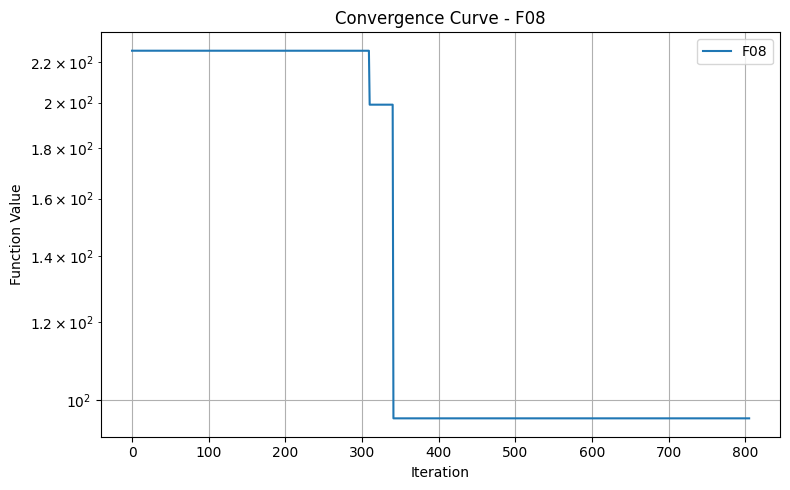

Running F09 (dim=30)...


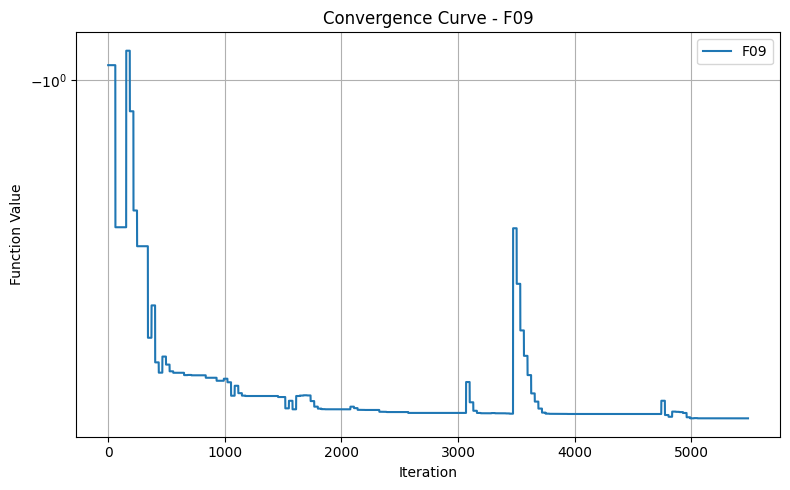

Running F10 (dim=30)...


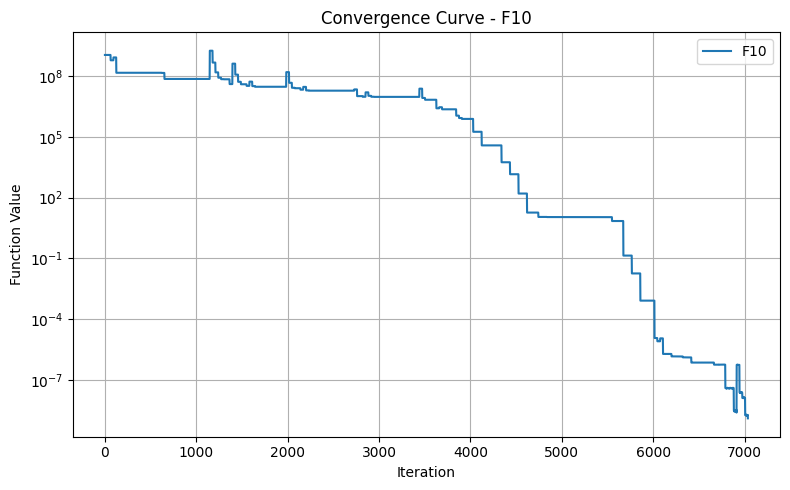

Running F11 (dim=30)...


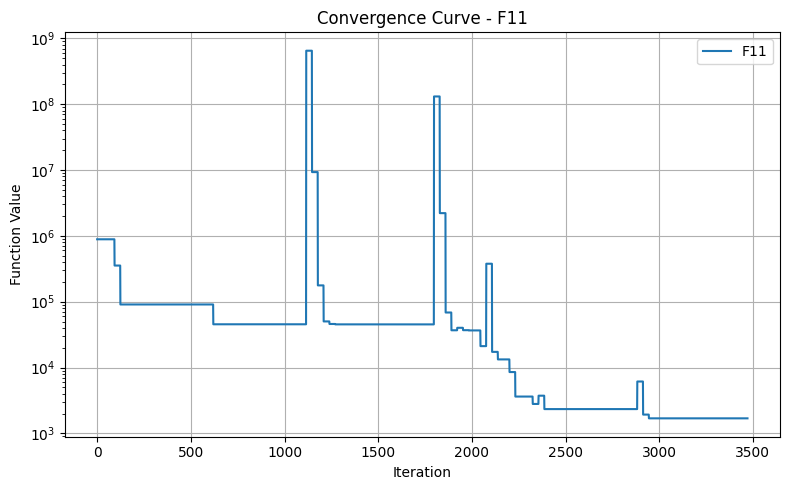

Running F12 (dim=30)...


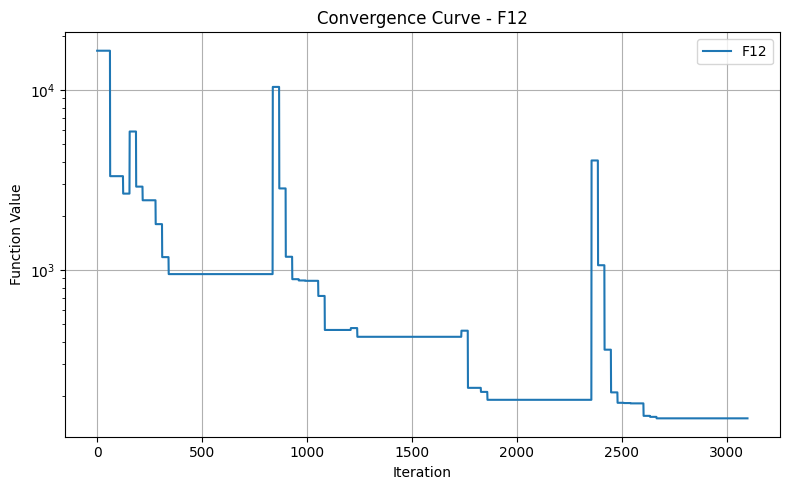

Running F13 (dim=30)...


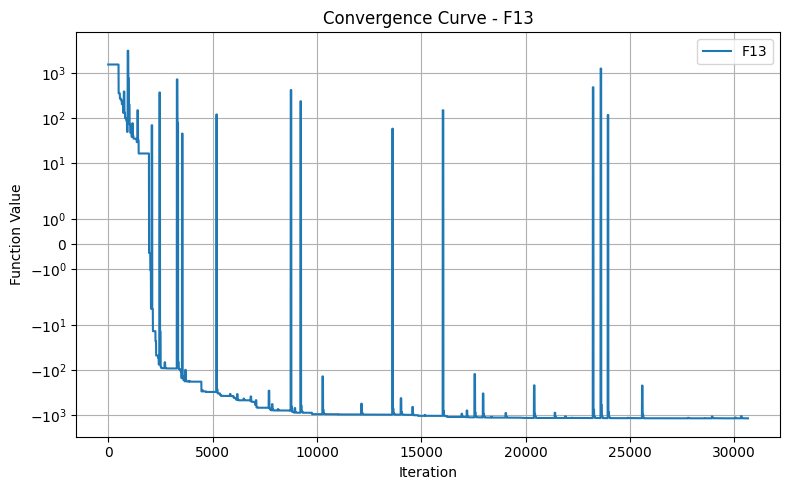

Running F14 (dim=30)...


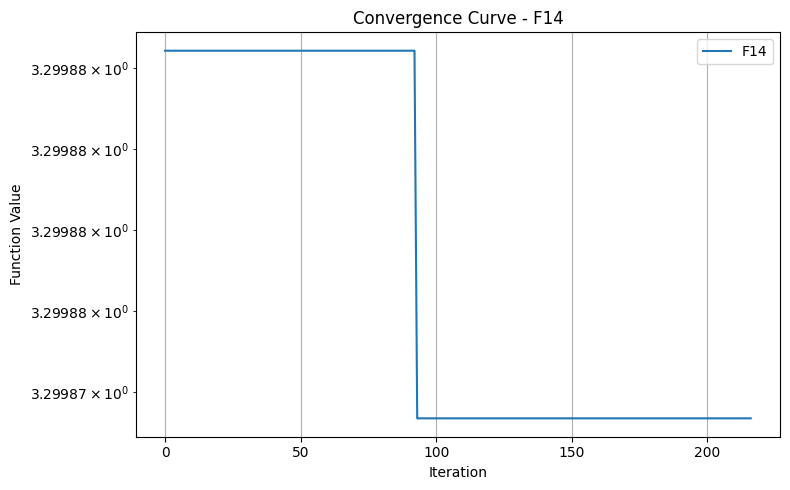

Running F15 (dim=30)...


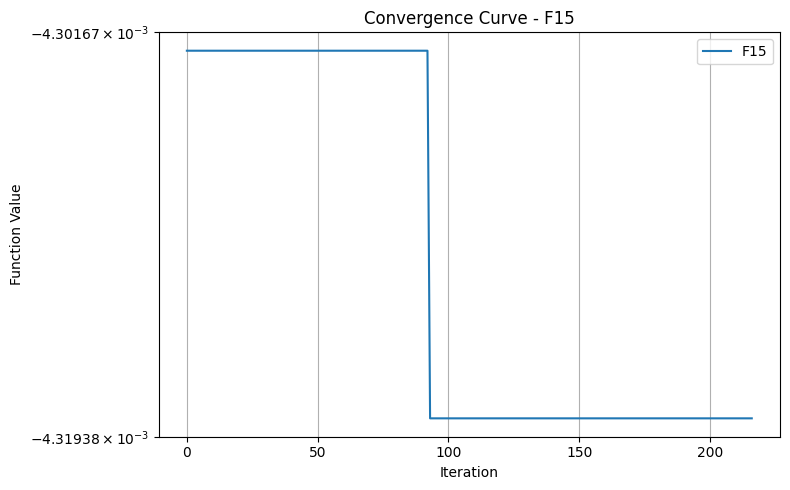

Running F16 (dim=2)...


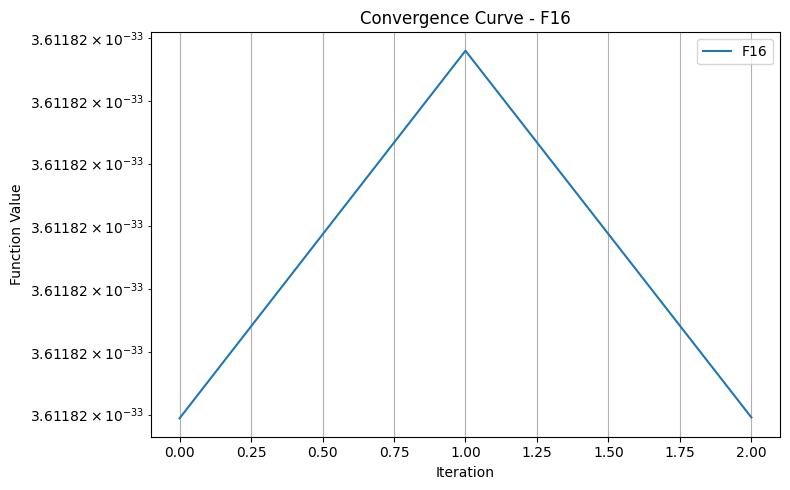

Running F17 (dim=2)...


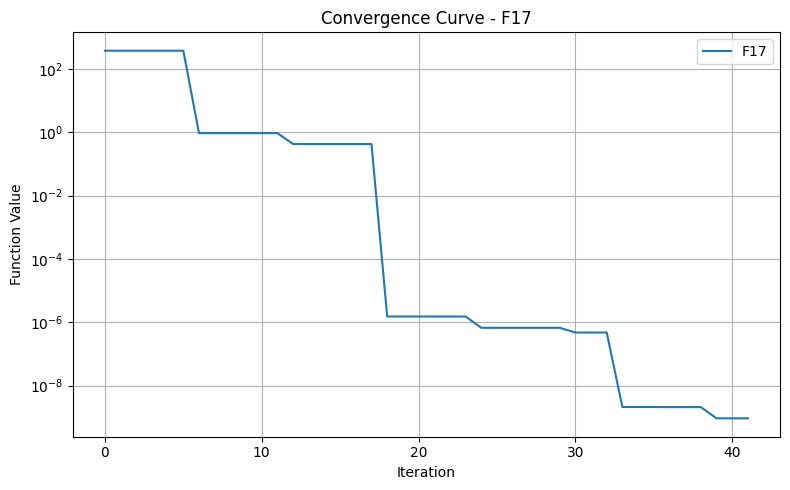

Running F18 (dim=2)...


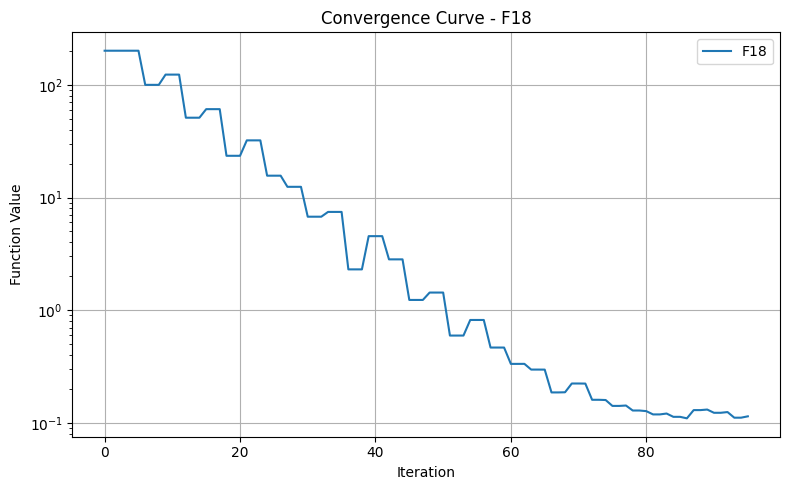

Running F19 (dim=2)...


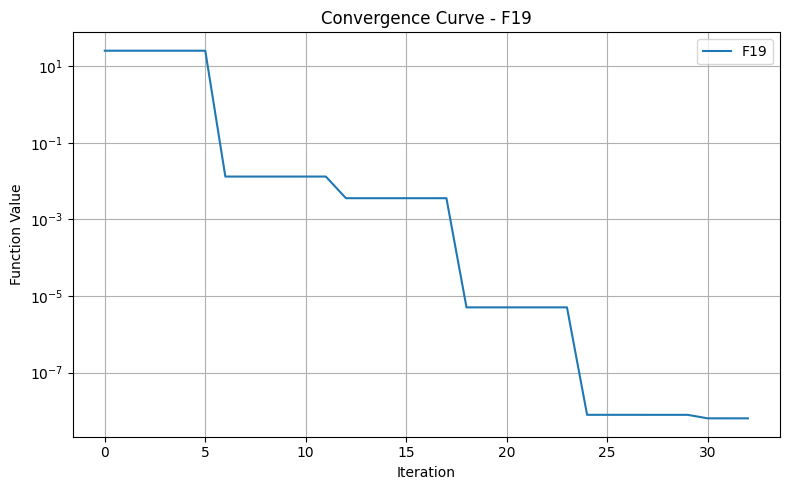

Running F20 (dim=2)...


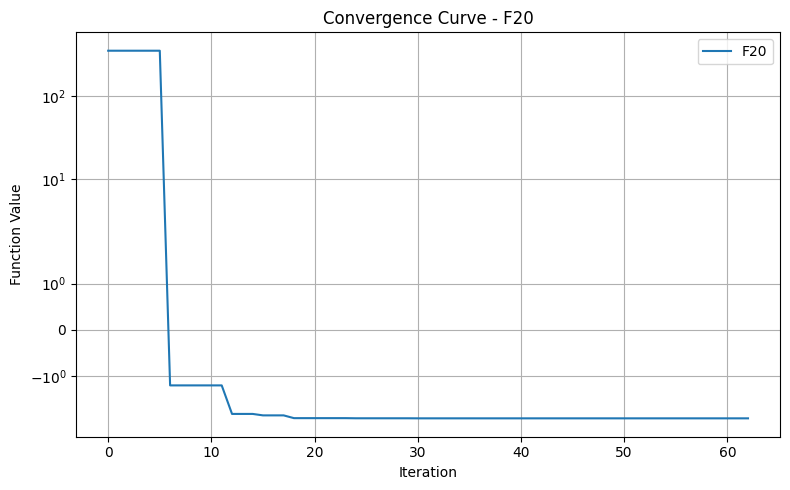

Running F21 (dim=2)...


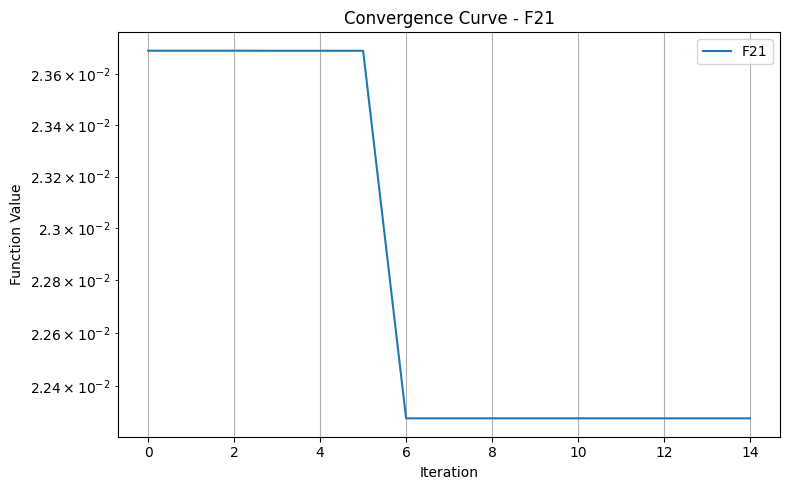

Running F22 (dim=2)...


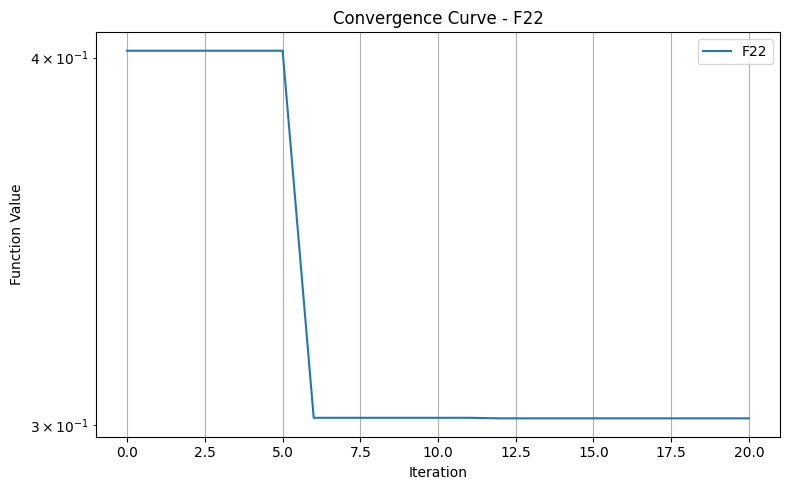

Running F23 (dim=2)...


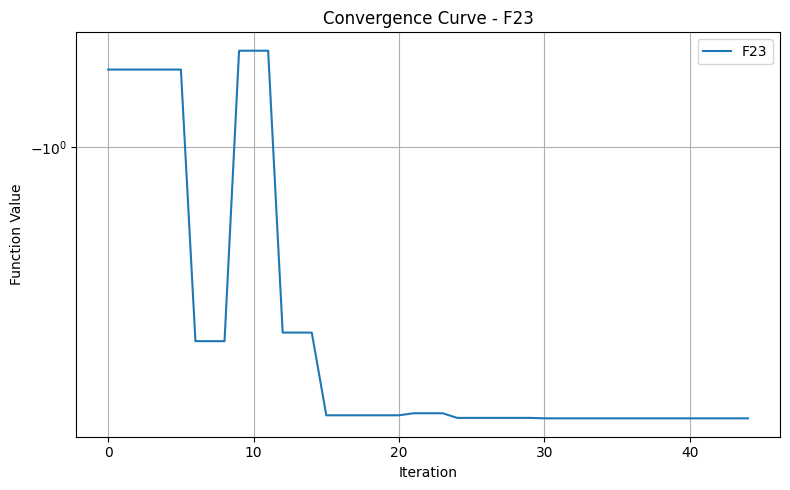


--- Benchmark Results ---
                  Best          Mean        Median         Worst           STD
Function                                                                      
F01       2.923260e-11  2.244501e+00  1.682465e-09  4.879277e+01  9.261778e+00
F02       1.177854e+01  2.280516e+04  5.601385e+01  4.701145e+05  8.746301e+04
F03       5.173626e+02  7.905565e+02  7.780388e+02  1.124276e+03  1.665650e+02
F04       8.589273e+00  1.285589e+01  1.324214e+01  1.462540e+01  1.413095e+00
F05       4.583361e-07  8.152289e-03  4.001776e-04  7.633130e-02  1.623034e-02
F06       7.021867e-09  3.787953e+01  3.133913e+00  2.948320e+02  7.225973e+01
F07      -4.656218e+03  1.044659e+04  1.216229e+04  1.233056e+04  3.790234e+03
F08       2.675999e+01  4.797478e+01  4.233225e+01  9.593223e+01  1.478256e+01
F09      -9.830803e+00 -7.118627e+00 -7.267833e+00 -4.079716e+00  1.687285e+00
F10       6.856694e-10  2.702813e+05  2.204272e-09  8.108439e+06  1.455509e+06
F11       3.463341e-10  1

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize
import warnings
import os

# --- Suppress warnings for clean output ---
warnings.filterwarnings("ignore", category=RuntimeWarning)

# --- Benchmark Functions (F1–F23) ---
def F1(x): return np.sum(x**2)
def F2(x): return np.sum(100 * (x[1:] - x[:-1]**2)**2 + (x[:-1] - 1)**2)
def F3(x): return np.sum(x**2 - 10 * np.cos(2 * np.pi * x) + 10)
def F4(x): return -20 * np.exp(-0.2*np.sqrt(np.mean(x**2))) - np.exp(np.mean(np.cos(2*np.pi*x))) + 20 + np.e
def F5(x): return np.sum(x**2)/4000 - np.prod(np.cos(x / np.sqrt(np.arange(1, len(x)+1)))) + 1
def F6(x): return np.sum(x**2) + (np.sum(0.5 * np.arange(1, len(x)+1) * x))**2 + (np.sum(0.5 * np.arange(1, len(x)+1) * x))**4
def F7(x): return 418.9829 * len(x) - np.sum(x * np.sin(np.sqrt(np.abs(x))))
def F8(x): 
    w = 1 + (x - 1) / 4
    return np.sin(np.pi * w[0])**2 + np.sum((w[:-1] - 1)**2 * (1 + 10*np.sin(np.pi*w[:-1] + 1)**2)) + (w[-1]-1)**2 * (1 + np.sin(2*np.pi*w[-1])**2)
def F9(x): return -np.sum(np.sin(x) * np.sin(((np.arange(1, len(x)+1) * x**2) / np.pi))**20)
def F10(x): return x[0]**2 + 1e6 * np.sum(x[1:]**2)
def F11(x): return np.sum(np.abs(x)**(2 + 4*np.arange(len(x))/(len(x)-1)))
def F12(x): return np.sum([np.sum(x[:i])**2 for i in range(1, len(x)+1)])
def F13(x): return np.sum((x - 1)**2) - np.sum(x[:-1] * x[1:])
def F14(x): return 1 - np.cos(2*np.pi*np.sqrt(np.sum(x**2))) + 0.1*np.sqrt(np.sum(x**2))
def F15(x): return - (1 + np.cos(12*np.sqrt(np.sum(x**2)))) / (0.5*np.sum(x**2) + 2)
def F16(x): return -np.cos(x[0]) * np.cos(x[1]) * np.exp(-(x[0]-np.pi)**2 - (x[1]-np.pi)**2)
def F17(x): return (x[0] + 2*x[1] - 7)**2 + (2*x[0] + x[1] - 5)**2
def F18(x): return 100*np.sqrt(abs(x[1] - 0.01*x[0]**2)) + 0.01*abs(x[0] + 10)
def F19(x): return 0.26*(x[0]**2 + x[1]**2) - 0.48*x[0]*x[1]
def F20(x): return np.sin(x[0]+x[1]) + (x[0]-x[1])**2 - 1.5*x[0] + 2.5*x[1] + 1
def F21(x): return 0.5 + (np.sin(x[0]**2 - x[1]**2)**2 - 0.5)/(1 + 0.001*(x[0]**2 + x[1]**2))**2
def F22(x): return 0.5 + (np.cos(np.sin(abs(x[0]**2 - x[1]**2)))**2 - 0.5)/(1 + 0.001*(x[0]**2 + x[1]**2))**2
def F23(x): 
    r = np.sqrt(x[0]**2 + x[1]**2)
    z = np.clip(abs(1 - r / np.pi), -50, 50)
    try:
        exp_term = np.exp(z)
    except:
        exp_term = 1e10
    return -abs(np.sin(x[0]) * np.cos(x[1]) * exp_term)

benchmark_functions = {
    f"F{str(i+1).zfill(2)}": f for i, f in enumerate([
        F1, F2, F3, F4, F5, F6, F7, F8, F9, F10, F11, F12, F13, F14, F15,
        F16, F17, F18, F19, F20, F21, F22, F23
    ])
}

# ----- TNC -----
def tnc(func, initial_guess):
    convergence_curve = []

    def wrapped_func(x):
        val = func(x)
        convergence_curve.append(val)
        return val

    result = minimize(
        fun=wrapped_func,
        x0=initial_guess,
        method='TNC',
        constraints=[],
        options={'maxfun': 1000, 'disp': False}
    )
    return result.x, result.fun, convergence_curve

# ----- Run Single Benchmark -----
def run_benchmark(func, dim, runs=30, low=-10, high=10):
    results = []
    convergence = None
    for _ in range(runs):
        x0 = np.random.uniform(low, high, size=dim)
        try:
            result, val, curve = tnc(func, x0)
            if np.isfinite(val):
                results.append(val)
                if convergence is None or (len(curve) < len(convergence)):
                    convergence = curve
        except Exception as e:
            print(f"[!] Error during benchmark run: {e}")
            results.append(np.nan)
    return {
        'Best': np.nanmin(results),
        'Mean': np.nanmean(results),
        'Median': np.nanmedian(results),
        'Worst': np.nanmax(results),
        'STD': np.nanstd(results),
        'Convergence': convergence
    }

# --- Run All Benchmarks with Plotting ---
def run_all_benchmarks(dim=30, runs=30, seed=None):
    if seed is not None:
        np.random.seed(seed)

    summary = []
    for name, func in benchmark_functions.items():
        d = 2 if name in ['F16','F17','F18','F19','F20','F21','F22','F23'] else dim
        print(f"Running {name} (dim={d})...")
        stats = run_benchmark(func, dim=d, runs=runs)
        convergence = stats.pop('Convergence')

        if convergence:
            plt.figure(figsize=(8, 5))
            plt.plot(convergence, label=name)
            if all(val > 0 for val in convergence):
                plt.yscale('log')
            else:
                plt.yscale('symlog')
            plt.xlabel('Iteration')
            plt.ylabel('Function Value')
            plt.title(f'Convergence Curve - {name}')
            plt.grid(True)
            plt.legend()
            plt.tight_layout()
            plt.show()

        stats['Function'] = name
        summary.append(stats)
    return pd.DataFrame(summary).set_index("Function")

# --- Execute All ---
results = run_all_benchmarks(dim=30, runs=30, seed=42)
print("\n--- Benchmark Results ---")
print(results)

# --- Save to Excel ---
output_path = '.'
os.makedirs(output_path, exist_ok=True)
excel_file = os.path.join(output_path, 'Benchmark_TNC.xlsx')
results.to_excel(excel_file)
print(f"\n✅ Results saved to {excel_file}")